In [1]:
!pip install -q librosa soundfile

import os
import zipfile
import librosa
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix

import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.utils import to_categorical

print("Libraries installed and imported successfully!")

Libraries installed and imported successfully!


In [2]:
import requests

url = "https://zenodo.org/records/1188976/files/Audio_Speech_Actors_01-24.zip"

response = requests.get(url)

with open("ravdess.zip", "wb") as f:
    f.write(response.content)

print("Dataset downloaded successfully!")

print(
    "File size:",
    round(os.path.getsize("ravdess.zip") / (1024 * 1024), 2),
    "MB"
)

Dataset downloaded successfully!
File size: 198.81 MB


In [3]:
extract_path = "RAVDESS"

with zipfile.ZipFile("ravdess.zip", "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

wav_files = []

for root, dirs, files in os.walk(extract_path):
    for file in files:
        if file.endswith(".wav"):
            wav_files.append(os.path.join(root, file))

print("Total WAV files:", len(wav_files))

Dataset extracted successfully!
Total WAV files: 1440


In [4]:
emotion_map = {
    1: "neutral",
    2: "calm",
    3: "happy",
    4: "sad",
    5: "angry",
    6: "fearful",
    7: "disgust",
    8: "surprised"
}

features = []
labels = []

for file in wav_files:

    try:
        parts = os.path.basename(file).split("-")
        emotion_code = int(parts[2])

        audio, sample_rate = librosa.load(file, duration=3)

        mfcc = librosa.feature.mfcc(
            y=audio,
            sr=sample_rate,
            n_mfcc=40
        )

        mfcc_mean = np.mean(mfcc.T, axis=0)

        features.append(mfcc_mean)
        labels.append(emotion_map[emotion_code])

    except Exception as e:
        print("Error:", file, e)

X = np.array(features)
y = np.array(labels)

print("Feature shape:", X.shape)
print("Label shape:", y.shape)

Feature shape: (1440, 40)
Label shape: (1440,)


happy        192
angry        192
calm         192
disgust      192
sad          192
fearful      192
surprised    192
neutral       96
Name: count, dtype: int64


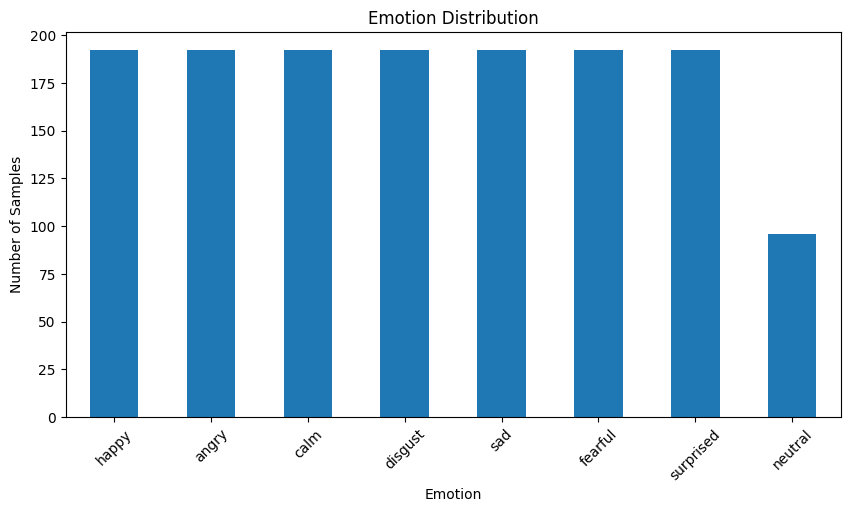

In [5]:
emotion_counts = pd.Series(y).value_counts()

print(emotion_counts)

plt.figure(figsize=(10, 5))
emotion_counts.plot(kind="bar")
plt.title("Emotion Distribution")
plt.xlabel("Emotion")
plt.ylabel("Number of Samples")
plt.xticks(rotation=45)
plt.show()

In [6]:
encoder = LabelEncoder()

y_encoded = encoder.fit_transform(y)
y_categorical = to_categorical(y_encoded)

print("Classes:")
print(encoder.classes_)

print("\nEncoded shape:", y_categorical.shape)

Classes:
['angry' 'calm' 'disgust' 'fearful' 'happy' 'neutral' 'sad' 'surprised']

Encoded shape: (1440, 8)


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_categorical,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 1152
Testing samples: 288


In [8]:
model = Sequential([
    Dense(256, activation="relu", input_shape=(40,)),
    Dropout(0.3),

    Dense(128, activation="relu"),
    Dropout(0.3),

    Dense(64, activation="relu"),
    Dropout(0.2),

    Dense(len(encoder.classes_), activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │        10,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 8)              │           520 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 52,168 (203.78 KB)

 Trainable params: 52,168 (203.78 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
history = model.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.1303 - loss: 25.8512 - val_accuracy: 0.1558 - val_loss: 3.9152
Epoch 2/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.1488 - loss: 8.1317 - val_accuracy: 0.0649 - val_loss: 2.4295
Epoch 3/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.1401 - loss: 3.9541 - val_accuracy: 0.1602 - val_loss: 2.0746
Epoch 4/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.1433 - loss: 2.6053 - val_accuracy: 0.1602 - val_loss: 2.0738
Epoch 5/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.1260 - loss: 2.2779 - val_accuracy: 0.1602 - val_loss: 2.0728
Epoch 6/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.1249 - loss: 2.1586 - val_accuracy: 0.1602 - val_loss: 2.0716
Epoch 7/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.1303 - loss: 2.1562 - val_accuracy: 0.1602 - val_loss: 2.0706
Epoch 8/30
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.1216 - loss: 2.1533 - val_accuracy: 0.1602 - val_los

In [10]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

Test Accuracy: 13.19%
Test Loss: 2.0629


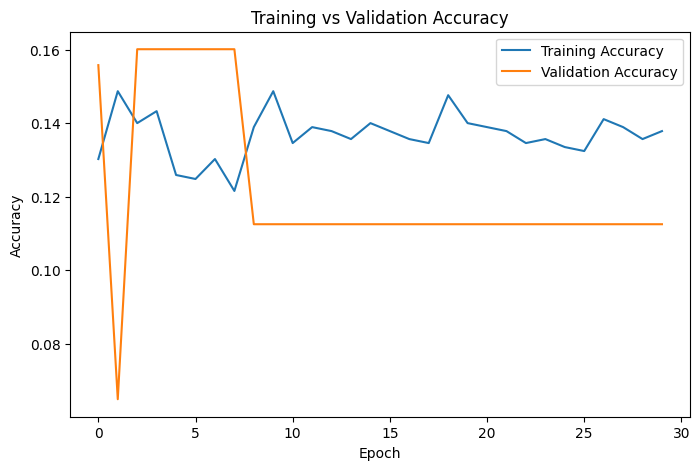

In [11]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.show()

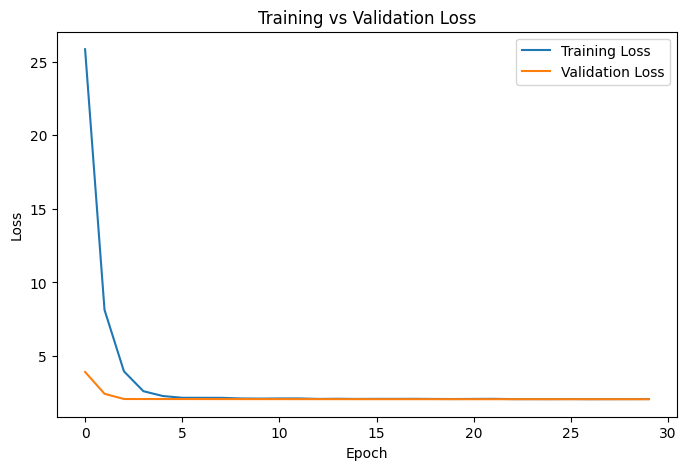

In [12]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.show()

In [13]:
y_pred = model.predict(X_test)

y_pred_classes = np.argmax(y_pred, axis=1)
y_test_classes = np.argmax(y_test, axis=1)

print(
    classification_report(
        y_test_classes,
        y_pred_classes,
        target_names=encoder.classes_
    )
)

9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step 
              precision    recall  f1-score   support

       angry       0.13      1.00      0.23        38
        calm       0.00      0.00      0.00        38
     disgust       0.00      0.00      0.00        38
     fearful       0.00      0.00      0.00        39
       happy       0.00      0.00      0.00        39
     neutral       0.00      0.00      0.00        19
         sad       0.00      0.00      0.00        38
   surprised       0.00      0.00      0.00        39

    accuracy                           0.13       288
   macro avg       0.02      0.12      0.03       288
weighted avg       0.02      0.13      0.03       288



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


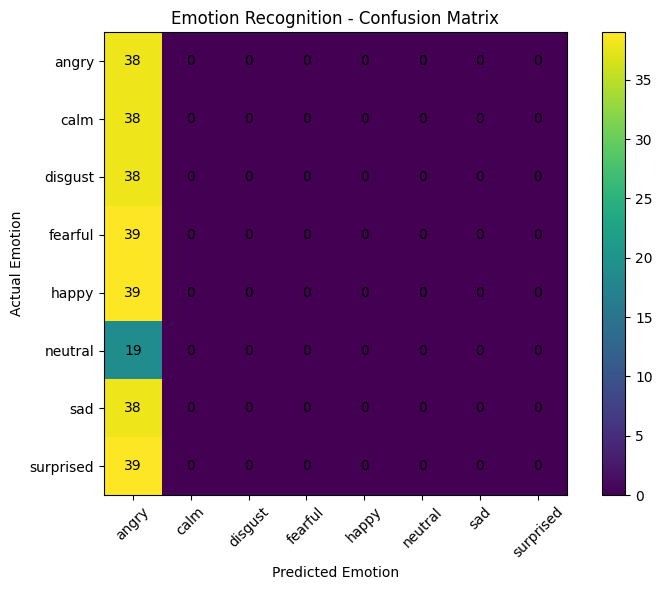

In [14]:
cm = confusion_matrix(
    y_test_classes,
    y_pred_classes
)

plt.figure(figsize=(8, 6))

plt.imshow(cm)
plt.colorbar()

plt.xticks(
    range(len(encoder.classes_)),
    encoder.classes_,
    rotation=45
)

plt.yticks(
    range(len(encoder.classes_)),
    encoder.classes_
)

plt.xlabel("Predicted Emotion")
plt.ylabel("Actual Emotion")
plt.title("Emotion Recognition - Confusion Matrix")

for i in range(len(cm)):
    for j in range(len(cm)):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.tight_layout()
plt.show()

In [17]:
# Select one WAV file from the RAVDESS dataset

import random

audio_path = random.choice(wav_files)

print("Testing audio file:")
print(audio_path)

# Load audio
audio, sample_rate = librosa.load(
    audio_path,
    duration=3
)

# Extract MFCC features
mfcc = librosa.feature.mfcc(
    y=audio,
    sr=sample_rate,
    n_mfcc=40
)

mfcc_mean = np.mean(mfcc.T, axis=0).reshape(1, -1)

# Predict emotion
prediction = model.predict(
    mfcc_mean,
    verbose=0
)

predicted_index = np.argmax(prediction)

predicted_emotion = encoder.inverse_transform(
    [predicted_index]
)[0]

confidence = prediction[0][predicted_index] * 100

print("\nPredicted Emotion:", predicted_emotion)
print(f"Confidence: {confidence:.2f}%")

Testing audio file:
RAVDESS/Actor_21/03-01-07-02-01-02-21.wav

Predicted Emotion: angry
Confidence: 13.97%


In [20]:
model.save("emotion_recognition_model.keras")

print("Model saved successfully!")

Model saved successfully!


In [21]:
print("===== Emotion Recognition from Speech =====")
print("Dataset: RAVDESS")
print("Feature Extraction: MFCC")
print("Model: Neural Network")
print("Number of Emotions:", len(encoder.classes_))
print("Test Accuracy:", f"{test_accuracy * 100:.2f}%")
print("===========================================")

===== Emotion Recognition from Speech =====
Dataset: RAVDESS
Feature Extraction: MFCC
Model: Neural Network
Number of Emotions: 8
Test Accuracy: 13.19%


In [22]:
print("Emotion Classes:")
for i, emotion in enumerate(encoder.classes_, start=1):
    print(f"{i}. {emotion}")

Emotion Classes:
1. angry
2. calm
3. disgust
4. fearful
5. happy
6. neutral
7. sad
8. surprised
